In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Problem 2a



In [3]:
data = pd.read_csv("market_data_2007_2025.csv")

print(data.head())
print(data.shape)
print(data.columns)

         Date  SPY_Adj_Close  SPY_Volume  QQQ_Adj_Close  TLT_Adj_Close  \
0  2007-04-11     101.122330   106365700      37.893623      48.060932   
1  2007-04-12     101.571693   115534400      38.193630      48.071945   
2  2007-04-13     102.035133    84287000      38.270779      47.923416   
3  2007-04-16     103.004082    83064600      38.622173      48.187450   
4  2007-04-17     103.277870   108424100      38.707901      48.456974   

   HYG_Adj_Close  VIX_Close  
0      31.546604      13.49  
1      31.567768      12.71  
2      31.510342      12.20  
3      31.498220      11.98  
4      31.483103      12.14  
(4713, 7)
Index(['Date', 'SPY_Adj_Close', 'SPY_Volume', 'QQQ_Adj_Close', 'TLT_Adj_Close',
       'HYG_Adj_Close', 'VIX_Close'],
      dtype='str')


In [4]:
data["Date"] = pd.to_datetime(data["Date"])
data = data.set_index("Date")

prices = data[
    [
        "SPY_Adj_Close",
        "QQQ_Adj_Close",
        "TLT_Adj_Close",
        "HYG_Adj_Close",
        "VIX_Close"
    ]
]

prices.columns = ["SPY", "QQQ", "TLT", "HYG", "VIX"]

# Daily log changes
log_changes = np.log(prices).diff().dropna()

# Financial series in rows, dates in columns
R = log_changes.T.to_numpy()

print("R shape:", R.shape)

R shape: (5, 4712)


In [5]:
# SPY daily log returns
r = log_changes["SPY"]

# Construct the eight predictors
X_features = pd.DataFrame(index=log_changes.index)

X_features["r_SPY"] = r
X_features["m5"] = r.rolling(window=5).sum()
X_features["RV20"] = np.sqrt((252 / 20) * r.pow(2).rolling(window=20).sum())
X_features["r_QQQ"] = log_changes["QQQ"]
X_features["r_TLT"] = log_changes["TLT"]
X_features["r_HYG"] = log_changes["HYG"]
X_features["dlogVIX"] = log_changes["VIX"]
X_features["logVIX"] = np.log(prices.loc[log_changes.index, "VIX"])

# Construct the response: annualized SPY volatility over the next five trading days
future_squared_returns = sum(
    log_changes["SPY"].shift(-h).pow(2)
    for h in range(1, 6)
)

Y = np.sqrt((252 / 5) * future_squared_returns).rename("Y")

# Record the date when the response becomes available
response_date = pd.Series(
    log_changes.index,
    index=log_changes.index
).shift(-5).rename("response_date")

# Combine predictors and response, retaining rows where everything is defined
model_data = X_features.join(Y).join(response_date).dropna()

print("Dataset shape:", model_data.shape)
print("\nColumns:")
print(model_data.columns.tolist())
print("\nFirst predictor date:", model_data.index.min())
print("Last predictor date:", model_data.index.max())
print("\nFirst few rows:")
display(model_data.head())

Dataset shape: (4688, 10)

Columns:
['r_SPY', 'm5', 'RV20', 'r_QQQ', 'r_TLT', 'r_HYG', 'dlogVIX', 'logVIX', 'Y', 'response_date']

First predictor date: 2007-05-09 00:00:00
Last predictor date: 2025-12-23 00:00:00

First few rows:


,r_SPY,m5,RV20,r_QQQ,r_TLT,r_HYG,dlogVIX,logVIX,Y,response_date
Date,,,,,,,,,,
2007-05-09,0.002716,0.010775,0.078504,0.002138,-0.003956,-0.002658,-0.025298,2.555676,0.108683,2007-05-16
2007-05-10,-0.010508,-0.005135,0.085478,-0.013761,0.002376,0.003605,0.054394,2.610070,0.080279,2007-05-17
2007-05-11,0.008521,-0.000397,0.089220,0.012692,-0.003510,0.000568,-0.048974,2.561096,0.081168,2007-05-18
2007-05-14,-0.002190,-0.002786,0.083037,-0.006863,-0.002612,-0.000094,0.075100,2.636196,0.079753,2007-05-21
2007-05-15,0.000266,-0.001194,0.082506,-0.007780,-0.000341,-0.000757,0.003575,2.639771,0.079926,2007-05-22


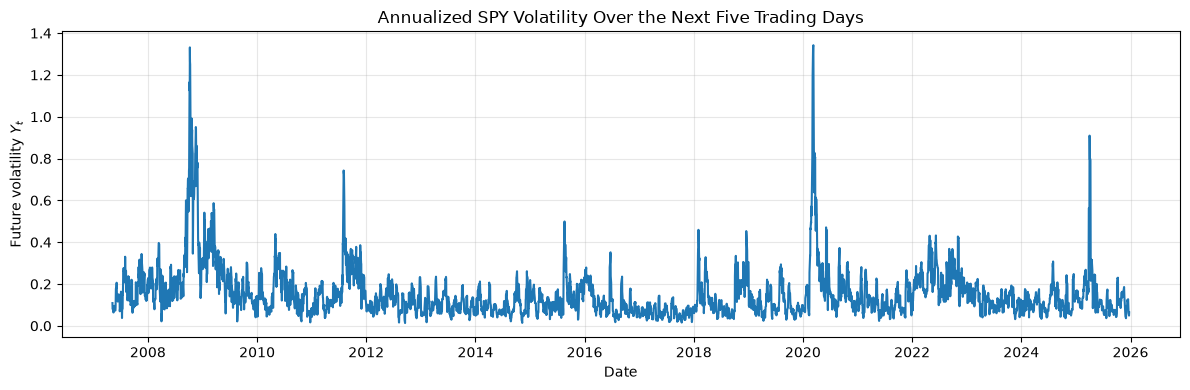

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(model_data.index, model_data["Y"])
plt.title("Annualized SPY Volatility Over the Next Five Trading Days")
plt.xlabel("Date")
plt.ylabel("Future volatility $Y_t$")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Select training rows: the response must be known by 31 December 2017
training = model_data.loc[
    model_data["response_date"] <= pd.Timestamp("2017-12-31")
]

feature_cols = X_features.columns.tolist()
X_raw_train = training[feature_cols]

# Standardize predictors using training-period means and standard deviations
X_train = (
    (X_raw_train - X_raw_train.mean())
    / X_raw_train.std(ddof=0)
).to_numpy()

# Compute X^T X / m
m, p = X_train.shape
G = X_train.T @ X_train / m

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(G)

# Sort from largest to smallest eigenvalue
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Number of training rows:", m)
print("Number of predictors:", p)
print("\nEigenvalues:")
print(pd.Series(
    eigenvalues,
    index=[f"d{i+1}" for i in range(p)]
).round(6))

print("\nEigenvectors (each column is an eigenvector):")
display(pd.DataFrame(
    eigenvectors,
    index=feature_cols,
    columns=[f"v{i+1}" for i in range(p)]
).round(4))

Number of training rows: 2677
Number of predictors: 8

Eigenvalues:
d1    3.566340
d2    1.843228
d3    0.860238
d4    0.687184
d5    0.521189
d6    0.309698
d7    0.138269
d8    0.073854
dtype: float64

Eigenvectors (each column is an eigenvector):


,v1,v2,v3,v4,v5,v6,v7,v8
r_SPY,-0.4976,0.0860,0.0159,-0.1479,0.0837,-0.3663,0.0021,0.7627
m5,-0.2936,-0.1291,-0.6473,0.6084,0.2824,0.1001,0.1320,-0.0287
RV20,0.0669,0.6933,-0.1396,0.1176,0.1041,0.0833,-0.6807,0.0217
r_QQQ,-0.4806,0.0823,0.0428,-0.1923,0.2000,-0.5257,-0.0594,-0.6353
r_TLT,0.2875,-0.0479,-0.6750,-0.6550,0.1571,-0.0659,0.0217,0.0310
r_HYG,-0.3851,0.0832,-0.2838,-0.1083,-0.8426,0.1804,-0.0234,-0.0965
dlogVIX,0.4266,-0.1109,-0.1503,0.3361,-0.3560,-0.7249,-0.1236,0.0503
logVIX,0.1334,0.6834,-0.0250,0.0592,-0.0310,-0.1003,0.7067,-0.0247


## 2b

In [9]:
# Rolling-window settings
W = 250
step = 21
lambdas = np.array([0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10])

feature_cols = X_features.columns.tolist()
X_all = model_data[feature_cols]
y_all = model_data["Y"].to_numpy()
dates = model_data.index
n, p = X_all.shape

def rolling_forecasts(start_date, last_refit_date):
    start_pos = np.flatnonzero(dates >= pd.Timestamp(start_date))[0]
    last_refit_pos = np.flatnonzero(dates <= pd.Timestamp(last_refit_date))[-1]
    refit_positions = np.arange(start_pos, last_refit_pos + 1, step)

    # Column 0 stores OLS forecasts; remaining columns store ridge forecasts
    predictions = np.full((n, len(lambdas) + 1), np.nan)
    baseline_predictions = np.full(n, np.nan)
    coefficient_history = []

    for t in refit_positions:
        refit_date = dates[t]

        # Use only observations whose future responses are already known
        train = model_data.loc[
            model_data["response_date"] <= refit_date
        ].tail(W)

        if len(train) != W:
            raise ValueError(f"Expected {W} training rows at {refit_date}")

        # Standardize predictors using this training window only
        X_train_raw = train[feature_cols]
        x_mean = X_train_raw.mean()
        x_std = X_train_raw.std(ddof=0)

        if (x_std == 0).any():
            raise ValueError(f"Zero predictor standard deviation at {refit_date}")

        Z_train = ((X_train_raw - x_mean) / x_std).to_numpy()

        # Center the response
        y_train = train["Y"].to_numpy()
        y_mean = y_train.mean()
        y_centered = y_train - y_mean

        # Closed-form OLS and ridge calculations
        m_train = len(train)
        G = Z_train.T @ Z_train / m_train
        q = Z_train.T @ y_centered / m_train
        beta_ols = np.linalg.solve(G, q)

        ridge_betas = {}
        for lam in lambdas:
            ridge_betas[float(lam)] = np.linalg.solve(
                G + lam * np.eye(p), q
            )

        # Forecast the next 21 rows, using training-window scaling
        block_positions = np.arange(t, min(t + step, n))
        X_future = X_all.iloc[block_positions]
        Z_future = ((X_future - x_mean) / x_std).to_numpy()

        predictions[block_positions, 0] = y_mean + Z_future @ beta_ols

        for j, lam in enumerate(lambdas, start=1):
            predictions[block_positions, j] = (
                y_mean + Z_future @ ridge_betas[float(lam)]
            )

        # Baseline: the mean response in the training window
        baseline_predictions[block_positions] = y_mean

        coefficient_history.append({
            "refit_date": refit_date,
            "beta_OLS": beta_ols,
            "beta_ridge": ridge_betas
        })

    return predictions, baseline_predictions, coefficient_history


# Refit every 21 rows, starting in 2018
predictions, baseline_predictions, coefficient_history = rolling_forecasts(
    start_date="2018-01-01",
    last_refit_date="2021-12-31"
)

print("Number of refits:", len(coefficient_history))
print("First refit:", coefficient_history[0]["refit_date"].date())
print("Last refit:", coefficient_history[-1]["refit_date"].date())
print("Prediction matrix shape:", predictions.shape)

Number of refits: 48
First refit: 2018-01-02
Last refit: 2021-12-02
Prediction matrix shape: (4688, 10)


In [10]:
# Validation period: forecast date from 2018 onwards,
# with the response known by 31 December 2021
validation_mask = (
    (model_data.index >= pd.Timestamp("2018-01-01"))
    & (model_data["response_date"] <= pd.Timestamp("2021-12-31"))
)

y_true = y_all[validation_mask]
y_pred = predictions[validation_mask]
y_baseline = baseline_predictions[validation_mask]

# Check that forecasts exist for every validation row
assert np.isfinite(y_pred).all()
assert np.isfinite(y_baseline).all()

# Common denominator: squared errors of the rolling-mean baseline
denominator = np.sum((y_true - y_baseline) ** 2)

# R-squared for OLS and each ridge penalty
squared_errors = np.sum((y_true[:, None] - y_pred) ** 2, axis=0)
r2_scores = 1 - squared_errors / denominator

score_names = ["OLS"] + [f"Ridge (λ={lam:g})" for lam in lambdas]
scores = pd.Series(r2_scores, index=score_names, name="R²_OOS")

display(scores.to_frame())

# Select the ridge penalty with the largest validation R-squared
best_idx = np.argmax(r2_scores[1:])
lambda_hat = lambdas[best_idx]

print(f"Best ridge lambda: {lambda_hat:g}")
print(f"Best ridge R²_OOS: {r2_scores[best_idx + 1]:.6f}")
print(f"OLS R²_OOS:        {r2_scores[0]:.6f}")

,R²_OOS
OLS,0.369171
Ridge (λ=0.001),0.372562
Ridge (λ=0.003),0.378802
Ridge (λ=0.01),0.396213
Ridge (λ=0.03),0.424911
Ridge (λ=0.1),0.456813
Ridge (λ=0.3),0.467866
Ridge (λ=1),0.433102
Ridge (λ=3),0.324450
Ridge (λ=10),0.166942


Best ridge lambda: 0.3
Best ridge R²_OOS: 0.467866
OLS R²_OOS:        0.369171


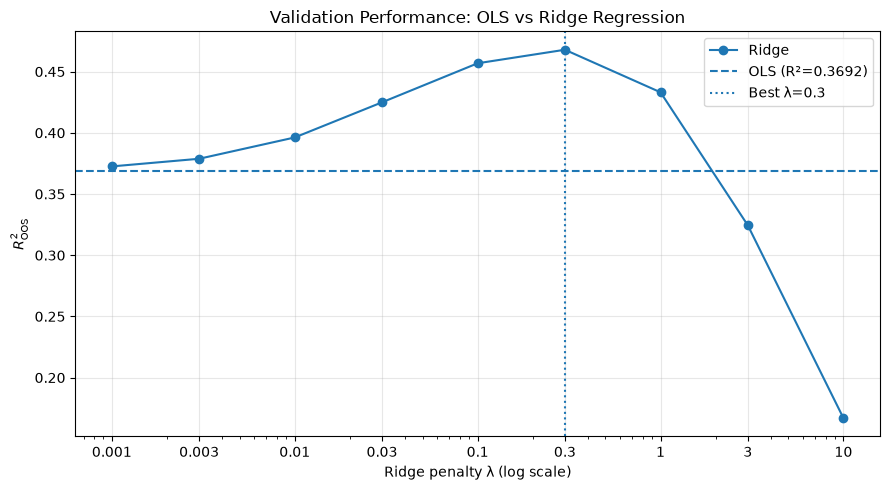

In [11]:
plt.figure(figsize=(9, 5))
plt.semilogx(
    lambdas, r2_scores[1:],
    marker="o", label="Ridge"
)
plt.axhline(
    r2_scores[0], linestyle="--",
    label=f"OLS (R²={r2_scores[0]:.4f})"
)
plt.axvline(
    lambda_hat, linestyle=":",
    label=f"Best λ={lambda_hat:g}"
)
plt.xticks(lambdas, [f"{lam:g}" for lam in lambdas])
plt.xlabel("Ridge penalty λ (log scale)")
plt.ylabel(r"$R^2_{\mathrm{OOS}}$")
plt.title("Validation Performance: OLS vs Ridge Regression")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 2c

In [12]:
lambda_hat = 0.3

# Collect the coefficients from each refit
beta_ols_refits = np.vstack([
    item["beta_OLS"] for item in coefficient_history
])

beta_ridge_refits = np.vstack([
    item["beta_ridge"][lambda_hat] for item in coefficient_history
])

# Find the column indices of the SPY and QQQ return coefficients
i_spy = feature_cols.index("r_SPY")
i_qqq = feature_cols.index("r_QQQ")

def coefficient_std(B):
    beta_spy = B[:, i_spy]
    beta_qqq = B[:, i_qqq]

    return pd.Series({
        "r_SPY coefficient": np.std(beta_spy, ddof=0),
        "r_QQQ coefficient": np.std(beta_qqq, ddof=0),
        "Sum of coefficients": np.std(beta_spy + beta_qqq, ddof=0),
        "Difference of coefficients": np.std(beta_spy - beta_qqq, ddof=0)
    })

stability = pd.DataFrame({
    "OLS": coefficient_std(beta_ols_refits),
    "Ridge (lambda=0.3)": coefficient_std(beta_ridge_refits)
})

display(stability)

,OLS,Ridge (lambda=0.3)
r_SPY coefficient,0.013740,0.001463
r_QQQ coefficient,0.019193,0.004265
Sum of coefficients,0.010591,0.003829
Difference of coefficients,0.031657,0.005099


In [13]:
# Repeat rolling forecasts for 2022–2025 using the previously selected lambda
lambda_hat = 0.3

predictions_22_25, baseline_22_25, history_22_25 = rolling_forecasts(
    start_date="2022-01-01",
    last_refit_date="2025-12-31"
)

print("Number of refits:", len(history_22_25))
print("First refit:", history_22_25[0]["refit_date"].date())
print("Last refit:", history_22_25[-1]["refit_date"].date())

Number of refits: 48
First refit: 2022-01-03
Last refit: 2025-12-09


In [14]:
# Evaluation period: predictor date in 2022–2025,
# with the future response known by 31 December 2025
mask_22_25 = (
    (model_data.index >= pd.Timestamp("2022-01-01"))
    & (model_data["response_date"] <= pd.Timestamp("2025-12-31"))
)

y_true_22_25 = y_all[mask_22_25]
y_base_22_25 = baseline_22_25[mask_22_25]

# Locate the ridge column corresponding to lambda = 0.3
ridge_idx = np.flatnonzero(np.isclose(lambdas, lambda_hat))[0] + 1

y_pred_ols = predictions_22_25[mask_22_25, 0]
y_pred_ridge = predictions_22_25[mask_22_25, ridge_idx]

# Use the same rolling-mean baseline for both models
denominator = np.sum((y_true_22_25 - y_base_22_25) ** 2)

r2_ols_22_25 = 1 - np.sum((y_true_22_25 - y_pred_ols) ** 2) / denominator
r2_ridge_22_25 = 1 - np.sum((y_true_22_25 - y_pred_ridge) ** 2) / denominator

comparison = pd.DataFrame({
    "2018–2021 validation": [
        r2_scores[0],
        r2_scores[ridge_idx]
    ],
    "2022–2025": [
        r2_ols_22_25,
        r2_ridge_22_25
    ]
}, index=["OLS", "Ridge (lambda=0.3)"])

comparison.loc["Ridge improvement"] = (
    comparison.loc["Ridge (lambda=0.3)"] - comparison.loc["OLS"]
)

display(comparison.round(4))

,2018–2021 validation,2022–2025
OLS,0.3692,0.3843
Ridge (lambda=0.3),0.4679,0.3964
Ridge improvement,0.0987,0.0121


# 3

In [ ]:
Z = (X - X.mean(axis=0)) / X.std(axis=0)
for t in refit:
    rows = np.arange(t - W, t)
    Zw, yw = Z[rows], y[rows] - y[rows].mean()
    beta = np.linalg.solve(Zw.T @ Zw + lam * np.eye(p), Zw.T @ yw)
    pred[t:t + 21] = y[rows].mean() + Z[t:t + 21] @ beta
lam_best = min(lams, key=lambda l: test_mse(l))
